In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [ ]:
project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "online_retail_II.xlsx"
data_path.exists()

True

In [3]:
df = pd.read_excel(
    data_path,
    sheet_name="Year 2010-2011"
)
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
541909,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [5]:
print(df.shape[1])
df.shape[0]

8


541910

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[us]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [7]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
})

missing

,missing_count,missing_pct
Invoice,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,135080,24.93
Country,0,0.00


In [8]:
print("Уникальных заказов:", df["Invoice"].nunique())
print("Уникальных товаров:", df["StockCode"].nunique())
print("Уникальных клиентов:", df["Customer ID"].nunique())

print("Минимальная дата:", df["InvoiceDate"].min())
print("Максимальная дата:", df["InvoiceDate"].max())

Уникальных заказов: 25900
Уникальных товаров: 4070
Уникальных клиентов: 4372
Минимальная дата: 2010-12-01 08:26:00
Максимальная дата: 2011-12-09 12:50:00


In [9]:
print("Полные дубликаты:", df.duplicated().sum())
print("Отрицательное количество товаров в заказе:", (df["Quantity"] < 0).sum())
print("Нулевая или отрицательная цена:", (df["Price"] <= 0).sum())

cancelled = (
    df["Invoice"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

print("Всего строк с отменами:", cancelled.sum())

Полные дубликаты: 5268
Отрицательное количество товаров в заказе: 10624
Нулевая или отрицательная цена: 2517
Всего строк с отменами: 9288


In [10]:
df[df["StockCode"] == "POST"][
    ["Invoice", "StockCode", "Description", "Quantity", "Price"]
].head(10)

,Invoice,StockCode,Description,Quantity,Price
45,536370,POST,POSTAGE,3,18.0
386,536403,POST,POSTAGE,1,15.0
1123,536527,POST,POSTAGE,1,18.0
5095,536840,POST,POSTAGE,1,18.0
5258,536852,POST,POSTAGE,1,18.0
5325,536858,POST,POSTAGE,2,40.0
5369,536861,POST,POSTAGE,3,18.0
6602,536967,POST,POSTAGE,1,18.0
6676,536974,POST,POSTAGE,2,18.0
6973,536983,POST,POSTAGE,1,18.0


In [11]:
df.loc[df["StockCode"] == "POST", "Description"].value_counts()

Description
POSTAGE    1253
Name: count, dtype: int64

**Первичная проверка.** В выборке 541 910 строк и 25 900 уникальных заказов: одна строка не всегда означает отдельный заказ. Почти у четверти строк нет `Customer ID` (24,93%), также обнаружены 5 268 полных дублей. Эти особенности нужно будет учесть при подготовке данных для разных моделей.


### Работа с отменами

In [12]:
# cancelled = (
#     df["Invoice"]
#     .astype("string")
#     .str.upper()
#     .str.startswith("C", na=False)
# )

print("Строки отмен:", cancelled.sum())

print(
    "Уникальные отменённые заказы:",
    df.loc[cancelled, "Invoice"].nunique()
)

Строки отмен: 9288
Уникальные отменённые заказы: 3836


In [13]:
negative_qty = df["Quantity"] < 0

pd.crosstab(
    cancelled,
    negative_qty,
    rownames=["Отменённый заказ"],
    colnames=["Отрицательное количество"],
    margins=True
)

Отрицательное количество,False,True,All
Отменённый заказ,,,
False,531286,1336,532622
True,0,9288,9288
All,531286,10624,541910


In [25]:
negative_without_cancel = df.loc[
    (df["Quantity"] < 0) & (~cancelled)
]

negative_without_cancel[
    ["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID"]
].tail(10)

,Invoice,StockCode,Description,Quantity,Price,Customer ID
535327,581204,85104,????damages????,-355,0.0,NaN
535328,581205,20893,damages,-55,0.0,NaN
535329,581206,21693,mixed up,-87,0.0,NaN
535330,581207,21688,mixed up,-337,0.0,NaN
535331,581208,72801C,check,-10,0.0,NaN
535333,581210,23395,check,-26,0.0,NaN
535335,581212,22578,lost,-1050,0.0,NaN
535336,581213,22576,check,-30,0.0,NaN
536910,581226,23090,missing,-338,0.0,NaN
538925,581422,23169,smashed,-235,0.0,NaN


In [23]:
negative_without_cancel["StockCode"].value_counts().head(10)

StockCode
85175     5
21830     5
85172     4
22719     4
82494L    4
72802C    4
21161     3
22162     3
22034     3
20966     3
Name: count, dtype: int64

In [24]:
print("Всего строк:", len(negative_without_cancel))
print(
    "Строк с нулевой ценой:",
    (negative_without_cancel["Price"] == 0).sum()
)
print(
    "Строк без Customer ID:",
    negative_without_cancel["Customer ID"].isna().sum()
)
print(
    "Уникальных Invoice:",
    negative_without_cancel["Invoice"].nunique()
)

Всего строк: 1336
Строк с нулевой ценой: 1336
Строк без Customer ID: 1336
Уникальных Invoice: 1336


In [27]:
negative_without_cancel["Description"].value_counts(
    dropna=False
).head(30)

Description
NaN                             862
check                           120
damages                          45
damaged                          42
?                                41
sold as set on dotcom            20
Damaged                          14
thrown away                       9
Unsaleable, destroyed.            9
??                                7
damages?                          5
wet damaged                       5
ebay                              5
smashed                           4
missing                           3
CHECK                             3
wet pallet                        3
Dotcom sales                      2
reverse 21/5/10 adjustment        2
counted                           2
crushed                           2
wet/rusty                         2
printing smudges/thrown away      2
sold as 1                         2
?missing                          2
incorrect stock entry.            2
stock check                       2
adjustment      

**Отмены и отрицательное количество** 

Все 9 288 строк с номером заказа на `C` имеют отрицательное количество (3 836 уникальных номеров). Ещё 1 336 отрицательных строк идут без `C`: у всех нулевая цена и отсутствует `Customer ID`. Описания вроде `check`, `damaged` и `lost` указывают, что это, скорее всего, внутренние складские корректировки, а не покупки клиентов.

### Нестандартные Stock Code

In [16]:
standard_code = (
    df["StockCode"]
    .astype("string")
    .str.fullmatch(r"\d{5}[A-Za-z]*", na=False)
)

special_items = df.loc[
    ~standard_code,
    ["StockCode", "Description"]
]

special_items.value_counts(dropna=False).head(25)

StockCode     Description                       
POST          POSTAGE                               1253
DOT           DOTCOM POSTAGE                         709
M             Manual                                 571
C2            CARRIAGE                               143
D             Discount                                77
S             SAMPLES                                 63
BANK CHARGES  Bank Charges                            37
AMAZONFEE     AMAZON FEE                              34
CRUK          CRUK Commission                         16
DCGSSGIRL     GIRLS PARTY BAG                         13
DCGSSBOY      BOYS PARTY BAG                          11
gift_0001_20  Dotcomgiftshop Gift Voucher £20.00       9
gift_0001_10  Dotcomgiftshop Gift Voucher £10.00       8
gift_0001_30  Dotcomgiftshop Gift Voucher £30.00       7
DCGS0003      BOXED GLASS ASHTRAY                      4
gift_0001_50  Dotcomgiftshop Gift Voucher £50.00       4
POST          NaN                      

 В `StockCode` встречаются не только товары, но и доставка (`POST`, `DOT`), скидки и другие операции. Необычный формат кода бывает и у реальных товаров или подарочных сертификатов. Поэтому удалять все нестандартные коды по одному шаблону не стоит.

### график

In [17]:
sales = df.loc[
    (~cancelled) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()
sales["LineAmount"] = sales["Quantity"] * sales["Price"]

In [18]:
monthly_sales = (
    sales
    .groupby(sales["InvoiceDate"].dt.to_period("M"))["LineAmount"]
    .sum()
)

monthly_sales.index = monthly_sales.index.to_timestamp()

monthly_sales

InvoiceDate
2010-12-01     823746.140
2011-01-01     691364.560
2011-02-01     523631.890
2011-03-01     717639.360
2011-04-01     537808.621
2011-05-01     770536.020
2011-06-01     761739.900
2011-07-01     719221.191
2011-08-01     759138.380
2011-09-01    1058590.172
2011-10-01    1154979.300
2011-11-01    1509496.330
2011-12-01     638810.680
Freq: MS, Name: LineAmount, dtype: float64

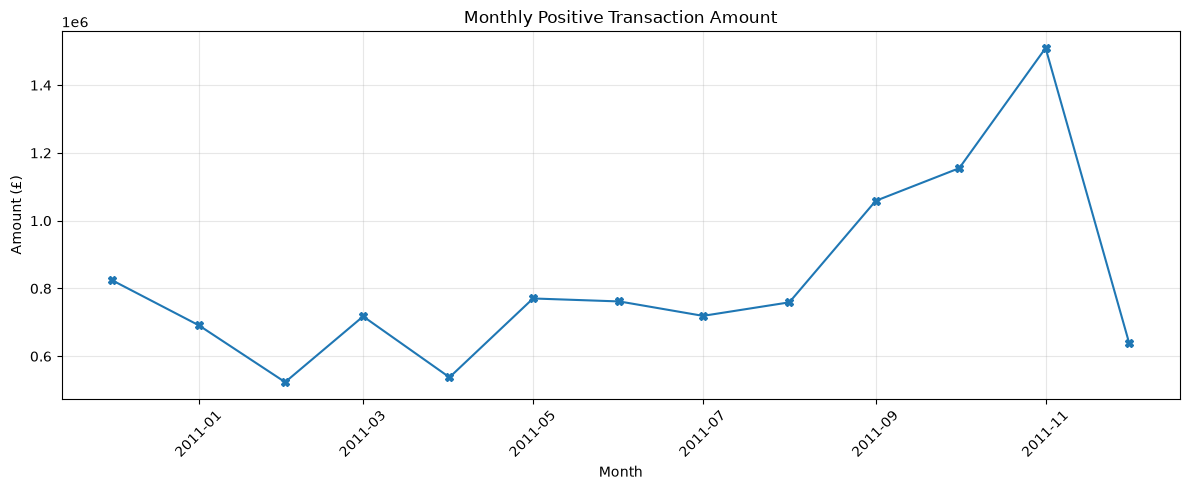

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="X"
)

plt.title("Monthly Positive Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Amount (£)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**С сентября по ноябрь 2011 года** сумма положительных операций растёт; максимум - в ноябре (около £1,51 млн). Декабрь 2011 года неполный так как данные заканчиваются 9 декабря, поэтому его снижение не говорит о падении спроса. Пока это не чистая выручка: в расчёт могли попасть дополнительные платные услуги.

### Продолжение исследования складских операций

In [28]:
adjustments = negative_without_cancel.copy()

adjustments["Month"] = (
    adjustments["InvoiceDate"].dt.to_period("M")
)

monthly_adjustments = (
    adjustments
    .groupby("Month")
    .agg(
        operations=("Invoice", "nunique"),
        units_removed=("Quantity", lambda x: -x.sum()),
        unique_products=("StockCode", "nunique")
    )
)

monthly_adjustments

,operations,units_removed,unique_products
Month,,,
2010-12,70,4046,70
2011-01,96,8905,91
2011-02,48,5835,46
2011-03,134,27683,122
2011-04,186,9433,181
2011-05,117,13166,111
2011-06,107,45352,105
2011-07,117,10395,115
2011-08,50,6471,45


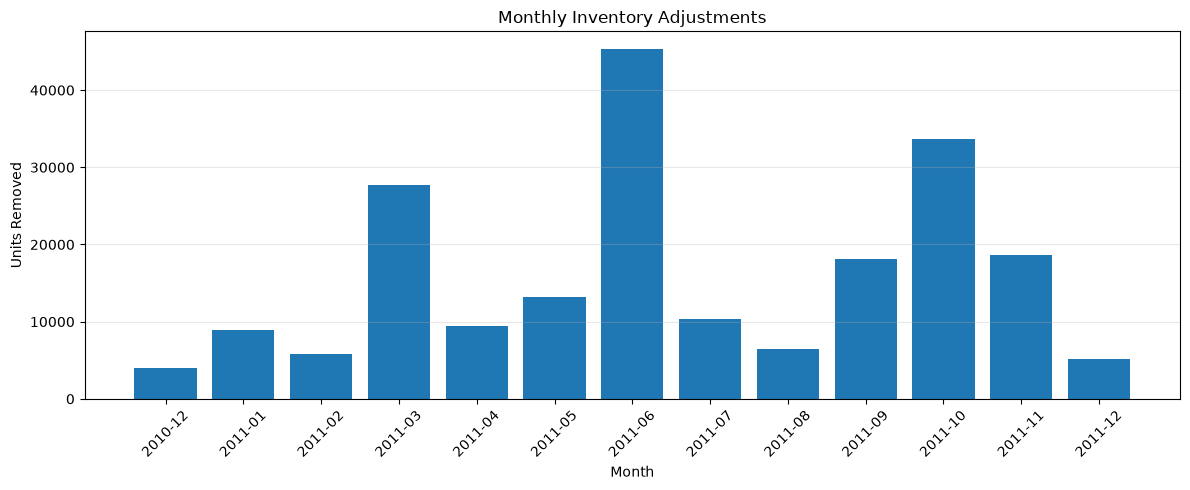

In [29]:
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_adjustments.index.astype(str),
    monthly_adjustments["units_removed"]
)

plt.title("Monthly Inventory Adjustments")
plt.xlabel("Month")
plt.ylabel("Units Removed")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
top_adjusted_products = (
    adjustments
    .groupby("StockCode")
    .agg(
        operations=("Invoice", "size"),
        total_removed=("Quantity", lambda x: -x.sum())
    )
    .sort_values("total_removed", ascending=False)
)

top_adjusted_products.head(15)

,operations,total_removed
StockCode,,
23005,2,19200
23003,1,9058
72140F,1,5368
79323W,1,4830
16045,2,4567
20713,3,3922
16259,1,3167
84598,1,3000
23270,1,2880


In [31]:
for month in ["2011-06", "2011-10"]:

    month_data = adjustments.loc[
        adjustments["Month"] == month
    ].copy()

    print(f"\nМесяц: {month}")

    display(
        month_data.nsmallest(10, "Quantity")[
            [
                "InvoiceDate",
                "StockCode",
                "Description",
                "Quantity"
            ]
        ]
    )


Месяц: 2011-06


,InvoiceDate,StockCode,Description,Quantity
225529,2011-06-14 10:37:00,23005,printing smudges/thrown away,-9600
225530,2011-06-14 10:37:00,23005,printing smudges/thrown away,-9600
225528,2011-06-14 10:36:00,23003,Printing smudges/thrown away,-9058
242906,2011-06-28 16:34:00,22618,"mouldy, unsaleable.",-1681
229728,2011-06-16 15:58:00,23113,Damaged,-1440
234762,2011-06-21 11:33:00,23114,Damaged,-1440
234763,2011-06-21 11:33:00,23115,Damaged,-1440
234764,2011-06-21 11:34:00,23116,Damaged,-1440
234765,2011-06-21 11:35:00,23117,Damaged,-1440
221186,2011-06-09 16:06:00,21700,sold as set on dotcom and amazon,-1206



Месяц: 2011-10


,InvoiceDate,StockCode,Description,Quantity
431381,2011-10-31 15:17:00,79323W,"Unsaleable, destroyed.",-4830
375429,2011-10-04 11:42:00,23270,incorrect stock entry.,-2880
431377,2011-10-31 15:16:00,79323LP,"Unsaleable, destroyed.",-2618
431378,2011-10-31 15:16:00,79323P,"Unsaleable, destroyed.",-2003
431375,2011-10-31 15:15:00,79323B,"Unsaleable, destroyed.",-1671
375427,2011-10-04 11:40:00,23268,Incorrect stock entry.,-1440
375428,2011-10-04 11:41:00,23269,incorrect stock entry.,-1440
431379,2011-10-31 15:16:00,79323GR,"Unsaleable, destroyed.",-1158
431383,2011-10-31 15:18:00,79342B,"Unsaleable, destroyed.",-1128
422751,2011-10-27 15:37:00,23343,wrongly coded 20713,-1000


In [32]:
df.loc[
    df["StockCode"].astype("string") == "23005",
    [
        "InvoiceDate",
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price"
    ]
].sort_values("InvoiceDate")

,InvoiceDate,Invoice,StockCode,Description,Quantity,Price
93670,2011-02-17 13:47:00,544304,23005,TRAVEL CARD WALLET I LOVE LONDON,2,0.42
93722,2011-02-17 14:04:00,544307,23005,TRAVEL CARD WALLET I LOVE LONDON,24,0.42
93781,2011-02-17 14:19:00,544311,23005,TRAVEL CARD WALLET I LOVE LONDON,1,0.42
93819,2011-02-17 14:36:00,544313,23005,TRAVEL CARD WALLET I LOVE LONDON,24,0.42
95066,2011-02-20 10:51:00,544444,23005,TRAVEL CARD WALLET I LOVE LONDON,5,0.42
...,...,...,...,...,...,...
535774,2011-12-08 09:20:00,581217,23005,TRAVEL CARD WALLET I LOVE LONDON,1,0.83
536217,2011-12-08 09:28:00,581219,23005,TRAVEL CARD WALLET I LOVE LONDON,2,0.83
539753,2011-12-08 16:30:00,581439,23005,TRAVEL CARD WALLET I LOVE LONDON,1,0.83
540034,2011-12-08 18:42:00,581456,23005,TRAVEL CARD WALLET I LOVE LONDON,10,0.42


 Крупные пики пришлись на март, июнь и октябрь 2011 года. Максимум - июнь (45 352 единицы). В июне по `23005` списано 19 200 единиц с пометкой о дефектах печати; в октябре встречаются крупные записи `Unsaleable, destroyed` и `incorrect stock entry`. Это похоже на отдельные складские события, но не доказывает изменения спроса. При прогнозировании покупок такие операции нужно будет учесть отдельно от продаж.